# hybrid-guard beyond wind: handing cases to an expert

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmed-ibrahim-asl/hybrid-guard/blob/main/examples/02_beyond_wind_expert_handoff.ipynb)

Any system that switches between predictors has the same trap: a model hands some cases to an expert, a larger model or a human. An overall accuracy check averages over every case, so it cannot tell a skilful hand-off from a harmful one. This notebook uses `cmat_classification` on two examples: a simulated expert reviewer, where the answer is known, and real handwritten digits from scikit-learn.

In [1]:
try:
    import hybrid_guard
except ImportError:  # Colab or a fresh environment
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "hybrid-guard"], check=True)
    import hybrid_guard
import numpy as np
import pandas as pd
from hybrid_guard import charts
print("hybrid-guard", hybrid_guard.__version__)

hybrid-guard 0.4.0


## 1. A simulated expert reviewer

A model is right 96% of the time on easy cases and 62% on hard ones, and it is less confident on the hard ones. A human reviewer is right 97% of the time on hard cases but only 85% on easy ones. Handing the reviewer the cases where the model is unsure should help; handing over a random set of cases of the same size should not.

In [2]:
from hybrid_guard import cmat_classification
rng = np.random.default_rng(1)
n = 20_000
y = rng.integers(0, 2, n)
hard = rng.random(n) < 0.25
model = np.where(rng.random(n) < np.where(hard, 0.62, 0.96), y, 1 - y)
reviewer = np.where(rng.random(n) < np.where(hard, 0.97, 0.85), y, 1 - y)
confidence = np.where(hard, rng.uniform(0.5, 0.75, n), rng.uniform(0.7, 1.0, n))
groups = np.arange(n) // 100           # cases arrive in batches of 100
unsure = confidence < 0.7
random_pick = rng.random(n) < unsure.mean()
results = {
    "Hand over unsure cases": cmat_classification(y, model, reviewer, unsure, groups=groups),
    "Hand over random cases": cmat_classification(y, model, reviewer, random_pick, groups=groups),
}
for name, r in results.items():
    print(name); print(r.summary()); print()

Hand over unsure cases
CMAT decision: ACCEPT
  rows 20,000, selected 3,947 (coverage 0.197), materially changed 1,564
  error rate 0.1256 -> 0.0547, difference -0.0709 [-0.0748, -0.0669]
  material harm 0.047 (upper 0.058), benefit 0.953, base rate 0.493
  - aggregate margin passed: error-rate change upper bound -0.0669 < 0.01
  - net benefit passed: lower bound of benefit minus harm +0.884
  - safety passed: harm upper bound 0.058 <= 0.1
  - skill passed: lower bound of (base rate - harm) +0.430

Hand over random cases
CMAT decision: REJECT
  rows 20,000, selected 3,847 (coverage 0.192), materially changed 863
  error rate 0.1256 -> 0.1244, difference -0.0012 [-0.0040, +0.0015]
  material harm 0.486 (upper 0.518), benefit 0.514, base rate 0.493
  - aggregate margin passed: error-rate change upper bound +0.0015 < 0.01
  - net benefit failed: lower bound of benefit minus harm -0.036
  - safety failed: harm upper bound 0.518 > 0.1
  - skill failed: lower bound of (base rate - harm) -0.02

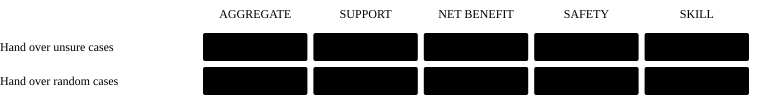

In [3]:
charts.conditions(results)

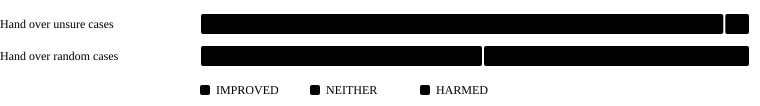

In [4]:
charts.changes(results)

Both hand-offs pass the aggregate check: the random one leaves the error rate where it was, well inside the one-point margin. Only CMAT shows the difference. The random hand-off changes the answer on hundreds of cases and about half of those changes are wrong, while handing over the unsure cases fixes almost every case it changes.

## 2. Real data: handwritten digits

A cheap model sees six principal components of each image; a random forest sees all pixels. The cheap model hands its unsure digits to the forest.

In [5]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
X, yd = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, yd, test_size=0.6, random_state=0, stratify=yd)
pca = PCA(n_components=6, random_state=0).fit(X_tr)
cheap = LogisticRegression(max_iter=2000).fit(pca.transform(X_tr), y_tr)
forest = RandomForestClassifier(n_estimators=300, random_state=0).fit(X_tr, y_tr)
p = cheap.predict_proba(pca.transform(X_te))
digits = cmat_classification(y_te, p.argmax(axis=1), forest.predict(X_te), p.max(axis=1) < 0.8,
                             groups=np.arange(len(y_te)))
print(digits.summary())

CMAT decision: REJECT
  rows 1,079, selected 291 (coverage 0.270), materially changed 98
  error rate 0.1270 -> 0.0593, difference -0.0677 [-0.0843, -0.0500]
  material harm 0.102 (upper 0.167), benefit 0.847, base rate 0.117
  - aggregate margin passed: error-rate change upper bound -0.0500 < 0.01
  - net benefit passed: lower bound of benefit minus harm +0.614
  - safety failed: harm upper bound 0.167 > 0.1
  - skill failed: lower bound of (base rate - harm) -0.018


The hand-off cuts the error rate a lot, so an accuracy check would accept it at once. CMAT does not: with about a thousand test digits, the forest overrode the cheap model on fewer than a hundred of them, and the upper bound of the share made wrong is still above 10%. The evidence is too thin to certify the hand-off case by case. That is the intended behaviour: collect more labelled cases, or improve the confidence signal, before relying on it.